# Домашнее задание 1. Рекомендации товаров

Буравов Глеб Олегович

Датасет: Amazon Reviews 2018, Musical Instruments, 5-core.
Источник: https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/

Цель — сравнить пять методов персональных top-10 рекомендаций товаров. Наблюдаемое взаимодействие — отзыв пользователя о товаре; релевантный товар при оценке — товар с оценкой 4 или 5.

## Запуск

Локально: распаковать проект, установить зависимости командой `python -m pip install -r requirements.txt`, открыть этот ноутбук из корня проекта и выполнить ячейки по порядку.

В Google Colab: загрузить этот ноутбук, выбрать «Среда → Выполнить все». Если моделей ещё нет в среде, первая ячейка предложит выбрать ZIP-архив проекта. GPU не требуется. Данные скачиваются автоматически в `data/musical_instruments/`, в GitHub их загружать не нужно.

## 1. Загрузка и очистка

Поля: `reviewerID` — пользователь, `asin` — товар, `overall` — оценка от 1 до 5, `unixReviewTime` — время отзыва в секундах Unix. Из метаданных используем бренд и категории; название нужно для описания товаров.

В исходном файле 231 392 отзыва. В четырёх используемых полях пропусков нет. Повторных пар пользователь–товар — 12 236; оставляем первую по времени запись, чтобы повторный отзыв не считался новым товаром. После очистки осталось 219 156 взаимодействий, 27 530 пользователей и 10 620 товаров.

Метаданные найдены для 99,92% товаров очищенной выборки, бренд или категории — для 99,60%. Отсутствующие признаки получают категорию `__unknown__`. Пустые метаданные не являются причиной удаления взаимодействий.


In [1]:
from pathlib import Path
import io
import zipfile
import importlib
import random
import json
import time

import numpy as np
import pandas as pd

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# В Colab при первом запуске загрузите архив проекта, если файлов моделей нет.
if not Path("models/fm.py").is_file():
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError("Запускайте ноутбук из корня распакованного проекта.")
    uploaded = files.upload()
    if len(uploaded) != 1:
        raise ValueError("Выберите один ZIP-архив проекта.")
    archive_bytes = next(iter(uploaded.values()))
    with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
        for entry in archive.infolist():
            target = (Path.cwd() / entry.filename).resolve()
            if not target.is_relative_to(Path.cwd().resolve()):
                raise ValueError("Небезопасный путь в архиве.")
        archive.extractall(".")
    if not Path("models/fm.py").is_file():
        raise FileNotFoundError("В архиве не найдена папка models в корне.")

from pathlib import Path
from urllib.parse import urljoin, urlparse
from html.parser import HTMLParser
import gzip
import html
import json

import pandas as pd
import requests

SOURCE = "https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/"
NEW_DATA = Path("data/musical_instruments")
NEW_DATA.mkdir(parents=True, exist_ok=True)

class SourceLinks(HTMLParser):
    def __init__(self):
        super().__init__()
        self.links = []

    def handle_starttag(self, tag, attrs):
        href = dict(attrs).get("href")
        if tag == "a" and href:
            self.links.append(urljoin(SOURCE, href))

response = requests.get(SOURCE, timeout=40)
response.raise_for_status()
parser = SourceLinks()
parser.feed(response.text)

def find_link(filename):
    matches = [
        url for url in parser.links
        if urlparse(url).path.endswith("/" + filename)
    ]
    if not matches:
        raise RuntimeError(f"Не найдена ссылка: {filename}")
    return matches[0]

def download(filename):
    path = NEW_DATA / filename
    url = find_link(filename)
    print("\nФайл:", filename)
    print("Источник:", url)

    if path.exists():
        print("Уже скачан.")
        return path

    temporary = path.with_suffix(".part")
    downloaded = 0
    next_report = 20 * 1024**2

    with requests.get(url, stream=True, timeout=(20, 90)) as response:
        response.raise_for_status()
        with temporary.open("wb") as file:
            for chunk in response.iter_content(1024**2):
                if chunk:
                    file.write(chunk)
                    downloaded += len(chunk)
                    if downloaded >= next_report:
                        print(f"Скачано {downloaded / 1024**2:.0f} МБ")
                        next_report += 20 * 1024**2

    temporary.replace(path)
    return path

reviews_path = download("Musical_Instruments_5.json.gz")
metadata_path = download("meta_Musical_Instruments.json.gz")

rows = []
with gzip.open(reviews_path, "rt", encoding="utf-8") as file:
    for line in file:
        record = json.loads(line)
        rows.append({
            "user_id": record.get("reviewerID"),
            "item_id": record.get("asin"),
            "rating": record.get("overall"),
            "timestamp": record.get("unixReviewTime"),
        })

new_raw = pd.DataFrame(rows)
new_df = new_raw.copy()

for column in ["rating", "timestamp"]:
    new_df[column] = pd.to_numeric(new_df[column], errors="coerce")

new_df = new_df.dropna(
    subset=["user_id", "item_id", "rating", "timestamp"]
)
new_df = new_df[new_df["rating"].between(1, 5)].copy()
new_df["timestamp"] = new_df["timestamp"].astype("int64")
new_df = (
    new_df.sort_values("timestamp", kind="stable")
          .drop_duplicates(["user_id", "item_id"], keep="first")
          .reset_index(drop=True)
)

needed = set(new_df["item_id"])

def clean(value):
    return " ".join(html.unescape(value).split()) if isinstance(value, str) else ""

def flatten(value):
    if isinstance(value, str):
        return [clean(value)]
    if isinstance(value, list):
        return [text for part in value for text in flatten(part)]
    return []

metadata = {}
with gzip.open(metadata_path, "rt", encoding="utf-8") as file:
    for line in file:
        record = json.loads(line)
        item_id = record.get("asin")
        if item_id not in needed or item_id in metadata:
            continue

        categories = flatten(
            record.get("category") or record.get("categories") or []
        )
        categories = sorted({
            value for value in categories
            if value and value.lower() != "musical instruments"
        })

        metadata[item_id] = {
            "item_id": item_id,
            "title": clean(record.get("title")),
            "brand": clean(record.get("brand")),
            "categories": categories,
        }

new_items = pd.DataFrame({"item_id": sorted(needed)})
if metadata:
    new_items = new_items.merge(
        pd.DataFrame(metadata.values()),
        on="item_id",
        how="left",
        validate="one_to_one"
    )
else:
    new_items["title"] = ""
    new_items["brand"] = ""
    new_items["categories"] = [[] for _ in range(len(new_items))]

for column in ["title", "brand"]:
    new_items[column] = new_items[column].fillna("")

new_items["categories"] = new_items["categories"].apply(
    lambda value: value if isinstance(value, list) else []
)

n_users = new_df["user_id"].nunique()
n_items = new_df["item_id"].nunique()
has_categories = new_items["categories"].map(bool)

has_brand = new_items["brand"].ne("")
coverage = len(metadata) / n_items
feature_coverage = (has_categories | has_brand).mean()

print("ИТОГОВАЯ ПРОВЕРКА")
print("Исходных отзывов:", len(new_raw))
print("После очистки:", len(new_df))
print("Пользователей:", n_users)
print("Товаров:", n_items)
print("Покрытие метаданными:", f"{coverage:.2%}")
print("Есть категории:", int(has_categories.sum()))
print("Есть бренд:", int(has_brand.sum()))
print("Покрытие категориями или брендом:", f"{feature_coverage:.2%}")

print("\nЧастые категории:")
print(new_items["categories"].explode().value_counts().head(10))

size_ok = (
    100_000 <= len(new_df) <= 2_000_000
    and n_users >= 1_000
    and n_items >= 1_000
)

if not size_ok:
    raise RuntimeError("Выборка не прошла ограничения по размеру.")

if coverage < 0.8 or feature_coverage < 0.5:
    raise RuntimeError("Покрытие метаданными требует проверки.")

new_df.to_csv(NEW_DATA / "interactions.csv", index=False)
new_items.to_json(
    NEW_DATA / "items.jsonl",
    orient="records",
    lines=True,
    force_ascii=False
)

DATA = NEW_DATA
df = new_df
items = new_items

print("\nПРОВЕРКА ПРОЙДЕНА. Рабочий датасет: Musical Instruments 2018.")
display(items[["item_id", "title", "brand", "categories"]].head())

Saving recsys_homework_1.zip to recsys_homework_1.zip

Файл: Musical_Instruments_5.json.gz
Источник: https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFilesSmall/Musical_Instruments_5.json.gz
Скачано 20 МБ

Файл: meta_Musical_Instruments.json.gz
Источник: https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/metaFiles2/meta_Musical_Instruments.json.gz
Скачано 20 МБ
Скачано 40 МБ
Скачано 60 МБ
Скачано 80 МБ
Скачано 100 МБ
Скачано 120 МБ
Скачано 140 МБ
Скачано 160 МБ
ИТОГОВАЯ ПРОВЕРКА
Исходных отзывов: 231392
После очистки: 219156
Пользователей: 27530
Товаров: 10620
Покрытие метаданными: 99.92%
Есть категории: 10330
Есть бренд: 10525
Покрытие категориями или брендом: 99.60%

Частые категории:
categories
Instrument Accessories        5006
Guitar & Bass Accessories     3251
Live Sound & Stage            1033
Amplifiers & Effects           940
Microphones & Accessories      852
Studio Recording Equipment     757
Guitar Effects                 707
Electric Guitar Effect

,item_id,title,brand,categories
0,0739079891,"Alfreds Teach Yourself to Play Ukulele, Comple...",Alfred Music Publishing,"[Ukuleles, Ukuleles, Mandolins & Banjos]"
1,0786615206,Guitar A-Frame Support,Sageworks,"[Guitar & Bass Accessories, Instrument Accesso..."
2,1480360295,ChordBuddy Guitar Learning System for Right Ha...,ChordBuddy,"[Guitar & Bass Accessories, Instrument Accesso..."
3,1928571018,Ernie Ball How to Play Guitar Phase 1 Book,Ernie Ball,"[General Accessories, Instrument Accessories]"
4,9792372326,"QSC K10 2-Way Powered Speaker - 1000 Watts, 1x10""",QSC,"[Live Sound & Stage, Monitors, Speakers & Subw..."


## 2. EDA, подвыборка и протокол

Пользователи и товары имеют неравномерную активность; у большинства мало взаимодействий. Оценки преимущественно высокие. Основная активность приходится на последние годы наблюдения. Поэтому случайное разбиение не используем.

Сначала определяем глобальные временные границы на очищенном полном датасете: train — до 27.02.2017, validation — с 27.02.2017 до 01.10.2017, test — с 01.10.2017. Отзывы с одинаковым timestamp не разделяем между соседними периодами.

Для уменьшения вычислений сортируем товары по числу взаимодействий только в train; при равенстве — по ID. Оставляем минимальный префикс, покрывающий не менее 110 000 обучающих взаимодействий, но не менее 1 000 товаров. Это даёт 1 816 товаров и 133 467 взаимодействий во всех периодах. Правило детерминировано и не использует популярность из validation/test. Это смещённая в сторону популярных товаров подвыборка, а не репрезентативная случайная выборка.

Train: 110 002 взаимодействия, 24 270 пользователей. Разреженность train — 99,750417%. В итоговой подвыборке бренд указан у 1 812 товаров, категории — у 1 773.

После ограничения каталогом исключаем из validation/test пользователей и товары, которых нет в train. В validation остаются 7 049 взаимодействий, в test — 6 232. Из-за холодного старта исключены соответственно 4 900 и 5 284 взаимодействия. Эта оценка относится только к тёплым пользователям и выбранному каталогу.

### Общие правила оценки

- Для каждой модели каталог кандидатов один: все 1 816 train-товаров минус товары из истории пользователя в train.
- Пользователь оценивается, если у него есть хотя бы один релевантный товар в соответствующем периоде: 3 313 пользователей на validation, 2 918 на test. Внутри каждого периода набор одинаков для всех моделей.
- Релевантность всегда определяется оценкой не ниже 4, независимо от обучающего таргета модели.
- Основная метрика заранее — NDCG@10; дополнительная — Recall@10. Метрики усредняем по пользователям, не по взаимодействиям.
- Каждая модель обучается только на train. Validation не добавляется в историю даже при финальном test; список исключаемых товаров также основан только на train.
- Отрицательные кандидаты при оценке не семплируются. При равных предсказаниях используется порядок индексов товаров, построенных из отсортированных ID.

Для множества релевантных товаров пользователя \(R_u\):

\[
\operatorname{Recall@10}(u)=\frac{|\operatorname{Top10}_u\cap R_u|}{|R_u|}.
\]

\[
\operatorname{DCG@10}(u)=\sum_{j=1}^{10}\frac{\mathbf{1}[i_j\in R_u]}{\log_2(j+1)},\qquad \operatorname{NDCG@10}(u)=\frac{\operatorname{DCG@10}(u)}{\sum_{j=1}^{\min(10,|R_u|)}1/\log_2(j+1)}.
\]

Recall отражает полноту списка, NDCG дополнительно учитывает позиции релевантных товаров.


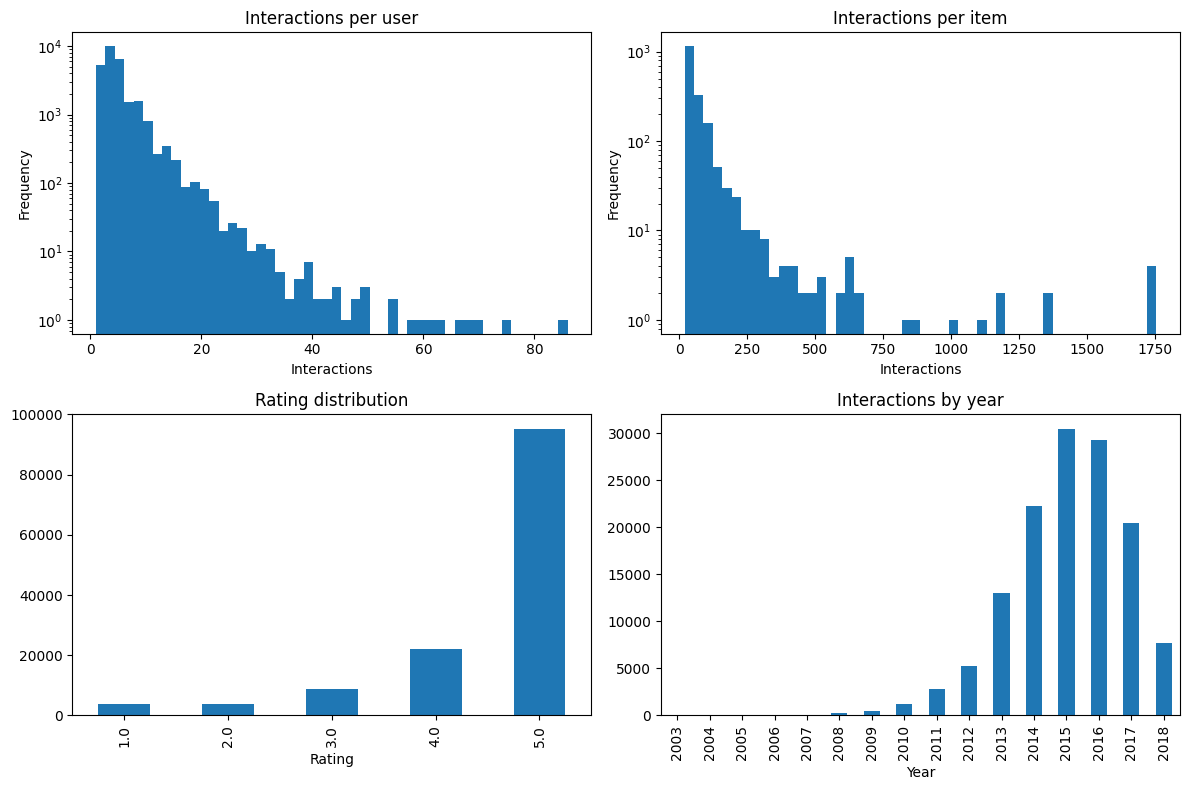

ПОДГОТОВКА ЗАВЕРШЕНА
Очищенный полный датасет: 219156
Итоговая подвыборка: 133467
Товаров в каталоге: 1816
Пользователей в train: 24270
Разреженность train: 99.750417%
Пропуски в полях взаимодействий: 0
Повторные пары user-item: 0
Начало validation: 2017-02-27 00:00:00+00:00
Начало test: 2017-10-01 00:00:00+00:00


,split,events,users,positive_events,excluded_cold_events
0,train,110002,24270,96732,0
1,validation,7049,3688,6169,4900
2,test,6232,3328,5295,5284


Пользователей с релевантными товарами в validation: 3313
Пользователей с релевантными товарами в test: 2918
КОНЕЦ БЛОКА ПОДГОТОВКИ


In [2]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse

SEED = 42
DATA = Path("data/musical_instruments")

full_df = pd.read_csv(
    DATA / "interactions.csv",
    dtype={"user_id": str, "item_id": str}
)
all_items = pd.read_json(
    DATA / "items.jsonl",
    orient="records",
    lines=True,
    dtype={"item_id": str}
)

# Границы определяем один раз на очищенном датасете.
t_validation = int(full_df["timestamp"].quantile(0.8))
t_test = int(full_df["timestamp"].quantile(0.9))

early = full_df[full_df["timestamp"] < t_validation]

# Отбор товаров использует только обучающий период.
popularity = (
    early.groupby("item_id")
         .size()
         .rename("count")
         .reset_index()
         .sort_values(
             ["count", "item_id"],
             ascending=[False, True],
             kind="stable"
         )
)

TARGET_TRAIN_EVENTS = 110_000

if popularity["count"].sum() < TARGET_TRAIN_EVENTS:
    raise RuntimeError("Недостаточно событий для выбранного правила отбора.")

n_selected = max(
    1000,
    int(np.searchsorted(
        popularity["count"].cumsum().to_numpy(),
        TARGET_TRAIN_EVENTS
    )) + 1
)

selected_ids = set(popularity.head(n_selected)["item_id"])
df = full_df[full_df["item_id"].isin(selected_ids)].copy()

assert 100_000 <= len(df) <= 2_000_000
assert df["user_id"].nunique() >= 1000
assert df["item_id"].nunique() >= 1000
assert not df.duplicated(["user_id", "item_id"]).any()

train = df[df["timestamp"] < t_validation].copy()
validation_raw = df[
    (df["timestamp"] >= t_validation)
    & (df["timestamp"] < t_test)
].copy()
test_raw = df[df["timestamp"] >= t_test].copy()

user_ids = sorted(train["user_id"].unique())
item_ids = sorted(train["item_id"].unique())

user_to_idx = {value: index for index, value in enumerate(user_ids)}
item_to_idx = {value: index for index, value in enumerate(item_ids)}

def keep_warm(frame):
    mask = (
        frame["user_id"].isin(user_to_idx)
        & frame["item_id"].isin(item_to_idx)
    )
    return frame[mask].copy()

validation = keep_warm(validation_raw)
test = keep_warm(test_raw)

for frame in [train, validation, test]:
    frame["u"] = frame["user_id"].map(user_to_idx).astype("int32")
    frame["i"] = frame["item_id"].map(item_to_idx).astype("int32")

n_users = len(user_ids)
n_items = len(item_ids)

X = sparse.csr_matrix(
    (
        np.ones(len(train), dtype=np.float32),
        (train["u"].to_numpy(), train["i"].to_numpy())
    ),
    shape=(n_users, n_items)
)

items = (
    all_items.set_index("item_id")
             .reindex(item_ids)
             .reset_index()
)

for column in ["title", "brand"]:
    items[column] = items[column].fillna("")

items["categories"] = items["categories"].apply(
    lambda value: list(value)
    if isinstance(value, (list, np.ndarray)) else []
)

summary = pd.DataFrame([
    {
        "split": "train",
        "events": len(train),
        "users": train["user_id"].nunique(),
        "positive_events": int((train["rating"] >= 4).sum()),
        "excluded_cold_events": 0
    },
    {
        "split": "validation",
        "events": len(validation),
        "users": validation["user_id"].nunique(),
        "positive_events": int((validation["rating"] >= 4).sum()),
        "excluded_cold_events": len(validation_raw) - len(validation)
    },
    {
        "split": "test",
        "events": len(test),
        "users": test["user_id"].nunique(),
        "positive_events": int((test["rating"] >= 4).sum()),
        "excluded_cold_events": len(test_raw) - len(test)
    }
])

# Небольшой EDA на итоговой подвыборке.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

df.groupby("user_id").size().plot.hist(
    bins=50, logy=True, ax=axes[0, 0]
)
axes[0, 0].set_title("Interactions per user")
axes[0, 0].set_xlabel("Interactions")

df.groupby("item_id").size().plot.hist(
    bins=50, logy=True, ax=axes[0, 1]
)
axes[0, 1].set_title("Interactions per item")
axes[0, 1].set_xlabel("Interactions")

df["rating"].value_counts().sort_index().plot.bar(ax=axes[1, 0])
axes[1, 0].set_title("Rating distribution")
axes[1, 0].set_xlabel("Rating")

years = pd.to_datetime(df["timestamp"], unit="s", utc=True).dt.year
years.value_counts().sort_index().plot.bar(ax=axes[1, 1])
axes[1, 1].set_title("Interactions by year")
axes[1, 1].set_xlabel("Year")

plt.tight_layout()
plt.show()

# Сохраняем разбиения и правило отбора.
for name, frame in [
    ("train", train),
    ("validation", validation),
    ("test", test)
]:
    frame.to_csv(DATA / f"{name}.csv", index=False)

with open(DATA / "protocol.json", "w", encoding="utf-8") as file:
    json.dump({
        "seed": SEED,
        "validation_start": t_validation,
        "test_start": t_test,
        "target_train_events": TARGET_TRAIN_EVENTS,
        "selected_items": item_ids,
        "relevance_rating_threshold": 4,
        "primary_metric": "NDCG@10",
        "secondary_metric": "Recall@10",
        "training_history": "train only"
    }, file, ensure_ascii=False, indent=2)

print("ПОДГОТОВКА ЗАВЕРШЕНА")
print("Очищенный полный датасет:", len(full_df))
print("Итоговая подвыборка:", len(df))
print("Товаров в каталоге:", n_items)
print("Пользователей в train:", n_users)
print("Разреженность train:", f"{1 - X.nnz / (n_users * n_items):.6%}")
print("Пропуски в полях взаимодействий:", int(df.isna().sum().sum()))
print("Повторные пары user-item:", int(
    df.duplicated(["user_id", "item_id"]).sum()
))
print("Начало validation:", pd.to_datetime(t_validation, unit="s", utc=True))
print("Начало test:", pd.to_datetime(t_test, unit="s", utc=True))

display(summary)

print(
    "Пользователей с релевантными товарами в validation:",
    validation.loc[validation["rating"] >= 4, "u"].nunique()
)
print(
    "Пользователей с релевантными товарами в test:",
    test.loc[test["rating"] >= 4, "u"].nunique()
)

print("КОНЕЦ БЛОКА ПОДГОТОВКИ")

## 3. Item-based CF и EASE

### Item-based CF

Бинарная матрица \(X\): единица для любого наблюдаемого train-взаимодействия. Для товаров \(i,j\):

\[
s_{ij}=\frac{X_{:i}^{\mathsf T}X_{:j}}{\|X_{:i}\|\,\|X_{:j}\|+\tau},\quad s_{ii}=0.
\]

Для каждого целевого товара оставляем \(k\) соседей с наибольшим сходством. Предсказание: \(\hat r_{ui}=\sum_jX_{uj}s_{ji}\). Соседи с нулевым сходством не влияют на результат.

### EASE

\[
\min_B\|X-XB\|_F^2+\lambda\|B\|_F^2,\qquad \operatorname{diag}(B)=0.
\]

\[
P=(X^{\mathsf T}X+\lambda I)^{-1},\qquad B_{ij}=-P_{ij}/P_{jj}\;(i\ne j),\quad B_{ii}=0.
\]

Предсказания — \(XB\). Обратная матрица вычисляется решением линейной системы, а не готовой рекомендательной моделью.

### Пространство поиска

ItemCF: `neighbors ∈ {50, 100}`, `shrink = 10`. EASE: `regularization ∈ {100, 500}`. Для каждого метода выбираем максимум validation NDCG@10.

Код обучения и предсказаний находится в `models/item_cf.py`, `models/ease.py`, общие рекомендации и метрики — в `evaluation.py`.


In [3]:
Path("results").mkdir(exist_ok=True)

importlib.invalidate_caches()

import models.item_cf as item_cf_module
import models.ease as ease_module
import evaluation as evaluation_module

importlib.reload(item_cf_module)
importlib.reload(ease_module)
importlib.reload(evaluation_module)

ItemCF = item_cf_module.ItemCF
EASE = ease_module.EASE
make_truth = evaluation_module.make_truth
evaluate = evaluation_module.evaluate

validation_truth = make_truth(validation)

assert len(validation_truth) == 3313
assert X.shape == (n_users, n_items)

for user, relevant in validation_truth.items():
    assert not relevant.intersection(X[user].indices)

configurations = [
    ("ItemCF", ItemCF, {"neighbors": 50, "shrink": 10.0}),
    ("ItemCF", ItemCF, {"neighbors": 100, "shrink": 10.0}),
    ("EASE", EASE, {"regularization": 100.0}),
    ("EASE", EASE, {"regularization": 500.0}),
]

validation_rows = []
best_models = {}
best_parameters = {}
best_validation_scores = {}

for name, model_class, parameters in configurations:
    print(f"Обучение {name}: {parameters}", flush=True)

    started = time.perf_counter()
    model = model_class(**parameters).fit(X)
    fit_seconds = time.perf_counter() - started

    started = time.perf_counter()
    metrics = evaluate(model, validation_truth, X)
    evaluation_seconds = time.perf_counter() - started

    row = {
        "model": name,
        "parameters": json.dumps(parameters, sort_keys=True),
        **metrics,
        "fit_seconds": fit_seconds,
        "evaluation_seconds": evaluation_seconds
    }
    validation_rows.append(row)

    if (
        name not in best_validation_scores
        or metrics["NDCG@10"] > best_validation_scores[name]
    ):
        best_models[name] = model
        best_parameters[name] = parameters
        best_validation_scores[name] = metrics["NDCG@10"]

    print(
        f"  NDCG@10={metrics['NDCG@10']:.5f}; "
        f"Recall@10={metrics['Recall@10']:.5f}; "
        f"обучение={fit_seconds:.1f} с; "
        f"оценка={evaluation_seconds:.1f} с",
        flush=True
    )

validation_results = pd.DataFrame(validation_rows)
validation_results.to_csv(
    "results/validation_first_models.csv",
    index=False
)

print("\nРЕЗУЛЬТАТЫ НА VALIDATION")
display(validation_results)

print("\nВыбранные параметры:")
print(json.dumps(best_parameters, ensure_ascii=False, indent=2))

print("КОНЕЦ БЛОКА ПЕРВЫХ МОДЕЛЕЙ")

Обучение ItemCF: {'neighbors': 50, 'shrink': 10.0}
  NDCG@10=0.03582; Recall@10=0.05916; обучение=0.1 с; оценка=0.2 с
Обучение ItemCF: {'neighbors': 100, 'shrink': 10.0}
  NDCG@10=0.03548; Recall@10=0.05767; обучение=0.1 с; оценка=0.2 с
Обучение EASE: {'regularization': 100.0}
  NDCG@10=0.03385; Recall@10=0.05683; обучение=0.5 с; оценка=0.6 с
Обучение EASE: {'regularization': 500.0}
  NDCG@10=0.03577; Recall@10=0.06177; обучение=0.5 с; оценка=0.6 с

РЕЗУЛЬТАТЫ НА VALIDATION


,model,parameters,NDCG@10,Recall@10,evaluated_users,fit_seconds,evaluation_seconds
0,ItemCF,"{""neighbors"": 50, ""shrink"": 10.0}",0.035819,0.059157,3313,0.086476,0.174970
1,ItemCF,"{""neighbors"": 100, ""shrink"": 10.0}",0.035481,0.057667,3313,0.081299,0.241842
2,EASE,"{""regularization"": 100.0}",0.033850,0.056828,3313,0.477960,0.597264
3,EASE,"{""regularization"": 500.0}",0.035765,0.061774,3313,0.451332,0.631563



Выбранные параметры:
{
  "ItemCF": {
    "neighbors": 50,
    "shrink": 10.0
  },
  "EASE": {
    "regularization": 500.0
  }
}
КОНЕЦ БЛОКА ПЕРВЫХ МОДЕЛЕЙ


## 4. Базовый iALS и собственный таргет

Обе модели минимизируют

\[
L=\sum_{u,i}c_{ui}(p_{ui}-a_u^{\mathsf T}b_i)^2+\lambda\left(\sum_u\|a_u\|^2+\sum_i\|b_i\|^2\right).
\]

Пусть \(O_{ui}\) — индикатор наблюдаемого train-взаимодействия. В обеих моделях \(c_{ui}=1+\alpha O_{ui}\). Базовый таргет: \(p_{ui}=O_{ui}\). Собственный таргет:

\[
p^{custom}_{ui}=\begin{cases}(r_{ui}-1)/4,&O_{ui}=1,\\0,&O_{ui}=0.\end{cases}
\]

Оценки 1, 2, 3, 4, 5 переходят в 0, 0.25, 0.5, 0.75, 1. Низкая оценка отличается от отсутствующего взаимодействия повышенным confidence. Нулевые значения наблюдаемого таргета сохраняются в разреженной структуре. Обоснование: факт отзыва не всегда означает положительное отношение к товару.

При фиксированных факторах товаров \(Y\) обновление пользователя:

\[
a_u=(Y^{\mathsf T}C_uY+\lambda I)^{-1}Y^{\mathsf T}C_up_u.
\]

Затем аналогично обновляем товары. Матрицу всех пар не создаём: базовое \(Y^{\mathsf T}Y\) дополняется поправкой по наблюдаемым взаимодействиям.

Для обеих моделей: `factors=32`, `alpha=20`, `iterations=8`, `seed=42`, `regularization ∈ {1, 10}`. Инициализация и confidence одинаковые, поэтому сравнение при равной регуляризации изолирует изменение таргета. Это не просто изменение весов или гиперпараметров.

Реализации: `models/ials.py`, `models/custom_ials.py`. Переиспользуется общий ALS-алгоритм, собственное преобразование рейтингов реализовано в отдельном файле.


In [4]:
importlib.invalidate_caches()

import models.ials as ials_module
import models.custom_ials as custom_ials_module

importlib.reload(ials_module)
importlib.reload(custom_ials_module)

ImplicitALS = ials_module.ImplicitALS
RatingTargetALS = custom_ials_module.RatingTargetALS

# Проверяем отображение оценок в собственный таргет.
assert np.allclose(
    RatingTargetALS.target_from_rating([1, 2, 3, 4, 5]),
    [0.0, 0.25, 0.5, 0.75, 1.0]
)

# Проверяем ALS-обновление по прямой плотной формуле.
tiny_preferences = sparse.csr_matrix(
    ([1.0, 0.0], ([0, 0], [0, 2])),
    shape=(1, 3)
)
tiny_fixed = np.array([
    [0.2, 0.1],
    [0.1, 0.4],
    [0.3, -0.2]
])
tiny_model = ImplicitALS(
    factors=2, regularization=1.0, alpha=3.0
)
actual = tiny_model._update(tiny_preferences, tiny_fixed)[0]

confidence = np.diag([4.0, 1.0, 4.0])
target = np.array([1.0, 0.0, 0.0])
expected = np.linalg.solve(
    tiny_fixed.T @ confidence @ tiny_fixed + np.eye(2),
    tiny_fixed.T @ confidence @ target
)
assert np.allclose(actual, expected)
print("Проверки таргета и ALS-обновления пройдены.")

als_rows = []

for regularization in [1.0, 10.0]:
    parameters = {
        "factors": 32,
        "regularization": regularization,
        "alpha": 20.0,
        "iterations": 8,
        "seed": 42
    }

    for name, model_class in [
        ("iALS", ImplicitALS),
        ("Custom_iALS", RatingTargetALS)
    ]:
        print(f"Обучение {name}: {parameters}", flush=True)
        started = time.perf_counter()

        model = model_class(**parameters)
        if name == "Custom_iALS":
            model.fit(X, train)
        else:
            model.fit(X)

        fit_seconds = time.perf_counter() - started

        started = time.perf_counter()
        metrics = evaluate(model, validation_truth, X)
        evaluation_seconds = time.perf_counter() - started

        row = {
            "model": name,
            "parameters": json.dumps(parameters, sort_keys=True),
            **metrics,
            "fit_seconds": fit_seconds,
            "evaluation_seconds": evaluation_seconds
        }
        als_rows.append(row)

        if (
            name not in best_validation_scores
            or metrics["NDCG@10"] > best_validation_scores[name]
        ):
            best_models[name] = model
            best_parameters[name] = parameters.copy()
            best_validation_scores[name] = metrics["NDCG@10"]

        print(
            f"  NDCG@10={metrics['NDCG@10']:.5f}; "
            f"Recall@10={metrics['Recall@10']:.5f}",
            flush=True
        )

als_results = pd.DataFrame(als_rows)
als_results.to_csv("results/validation_als.csv", index=False)

validation_results = pd.concat(
    [
        pd.read_csv("results/validation_first_models.csv"),
        als_results
    ],
    ignore_index=True
)
validation_results.to_csv("results/validation.csv", index=False)

print("\nРЕЗУЛЬТАТЫ ALS НА VALIDATION")
display(als_results)

print("\nЛучшие параметры четырёх моделей:")
print(json.dumps(best_parameters, ensure_ascii=False, indent=2))

print("КОНЕЦ БЛОКА ALS")

Проверки таргета и ALS-обновления пройдены.
Обучение iALS: {'factors': 32, 'regularization': 1.0, 'alpha': 20.0, 'iterations': 8, 'seed': 42}
    epoch 1/8: 1.7 sec
    epoch 2/8: 1.6 sec
    epoch 3/8: 1.7 sec
    epoch 4/8: 2.2 sec
    epoch 5/8: 1.7 sec
    epoch 6/8: 1.6 sec
    epoch 7/8: 1.6 sec
    epoch 8/8: 1.7 sec
  NDCG@10=0.03438; Recall@10=0.05918
Обучение Custom_iALS: {'factors': 32, 'regularization': 1.0, 'alpha': 20.0, 'iterations': 8, 'seed': 42}
    epoch 1/8: 1.6 sec
    epoch 2/8: 2.2 sec
    epoch 3/8: 1.8 sec
    epoch 4/8: 1.7 sec
    epoch 5/8: 1.6 sec
    epoch 6/8: 1.7 sec
    epoch 7/8: 1.6 sec
    epoch 8/8: 1.6 sec
  NDCG@10=0.03056; Recall@10=0.05254
Обучение iALS: {'factors': 32, 'regularization': 10.0, 'alpha': 20.0, 'iterations': 8, 'seed': 42}
    epoch 1/8: 2.1 sec
    epoch 2/8: 1.7 sec
    epoch 3/8: 1.6 sec
    epoch 4/8: 1.6 sec
    epoch 5/8: 1.6 sec
    epoch 6/8: 1.7 sec
    epoch 7/8: 2.3 sec
    epoch 8/8: 1.9 sec
  NDCG@10=0.03576; Recall@10

,model,parameters,NDCG@10,Recall@10,evaluated_users,fit_seconds,evaluation_seconds
0,iALS,"{""alpha"": 20.0, ""factors"": 32, ""iterations"": 8...",0.034383,0.059183,3313,13.780061,0.545352
1,Custom_iALS,"{""alpha"": 20.0, ""factors"": 32, ""iterations"": 8...",0.030558,0.052542,3313,13.874608,0.646531
2,iALS,"{""alpha"": 20.0, ""factors"": 32, ""iterations"": 8...",0.035758,0.061401,3313,14.497882,0.523775
3,Custom_iALS,"{""alpha"": 20.0, ""factors"": 32, ""iterations"": 8...",0.032118,0.055449,3313,13.741818,0.537581



Лучшие параметры четырёх моделей:
{
  "ItemCF": {
    "neighbors": 50,
    "shrink": 10.0
  },
  "EASE": {
    "regularization": 500.0
  },
  "iALS": {
    "factors": 32,
    "regularization": 10.0,
    "alpha": 20.0,
    "iterations": 8,
    "seed": 42
  },
  "Custom_iALS": {
    "factors": 32,
    "regularization": 10.0,
    "alpha": 20.0,
    "iterations": 8,
    "seed": 42
  }
}
КОНЕЦ БЛОКА ALS


## 5. Факторизационная машина

Используем бинарные признаки: ID пользователя, ID товара, бренд и категории товара. Бренд связывает товары одного производителя, категории — товары сходного назначения; ID отвечают за персональные и товарные эффекты. Несколько категорий кодируются multi-hot. Словарь строится по товарам train-каталога.

\[
\hat y(x)=w_0+\sum_jw_jx_j+\frac12\sum_f\left[\left(\sum_jv_{jf}x_j\right)^2-\sum_jv_{jf}^2x_j^2\right].
\]

Обучаем на бинарной кросс-энтропии от логита. Для наблюдаемых отзывов метка — `rating >= 4`. На каждое наблюдаемое взаимодействие добавляем два отрицательных примера — равномерно выбранных товара, которых нет в train-истории этого пользователя. Семплирование с возвращением, отрицательная выборка фиксируется на все эпохи одного запуска. Validation и test при семплировании не просматриваем; возможные будущие положительные товары могут попасть в обучающие отрицательные — ограничение подхода. При оценке используем полный каталог, как у остальных методов.

Оптимизатор Adam применяется к собственной формуле FM. Поиск: `factors ∈ {16, 32}`; фиксировано `learning_rate=0.01`, `weight_decay=1e-5`, `epochs=5`, `negatives=2`, `batch_size=2048`, `seed=42`. Выбор — по validation NDCG@10. Контроль: ещё одна FM только с ID, с настройками выбранной FM, без отдельного подбора.

Используются только бренд и категории, рассматриваемые как статические характеристики. Не используются цена, rank, also_buy, also_view, будущие отзывы или целевые статистики. Однако исходные метаданные — статический снимок без истории изменений: фактическую доступность каждого значения в прошлом проверить нельзя. Это допущение и ограничение временного эксперимента, а не доказанная point-in-time корректность.

Реализация: `models/fm.py`. В предсказании попарные члены перегруппированы в произведение пользовательских векторов на агрегированные товарные векторы; равенство прямой формуле проверяется в коде.


In [5]:
import importlib
import json
import time

import numpy as np
import pandas as pd
import torch

importlib.invalidate_caches()
import models.fm as fm_module
importlib.reload(fm_module)

FMRecommender = fm_module.FMRecommender
fm_rows = []

for factors in [16, 32]:
    parameters = {
        "factors": factors,
        "learning_rate": 0.01,
        "weight_decay": 1e-5,
        "epochs": 5,
        "negatives": 2,
        "batch_size": 2048,
        "seed": 42,
        "use_metadata": True
    }

    print(f"\nОбучение FM: {parameters}", flush=True)
    started = time.perf_counter()
    model = FMRecommender(**parameters).fit(X, train, items)
    fit_seconds = time.perf_counter() - started

    # Проверка совпадения быстрого предсказания с формулой сети.
    check_users = np.array([0, 1, 2])
    check_items = np.array([0, 1, 2])

    with torch.no_grad():
        direct = model.network_(
            torch.from_numpy(check_users),
            model.item_features_[torch.from_numpy(check_items)]
        ).numpy()

    fast = model.score(check_users)[np.arange(3), check_items]
    assert np.allclose(direct, fast, atol=1e-5)

    started = time.perf_counter()
    metrics = evaluate(model, validation_truth, X)
    evaluation_seconds = time.perf_counter() - started

    fm_rows.append({
        "model": "FM",
        "parameters": json.dumps(parameters, sort_keys=True),
        **metrics,
        "fit_seconds": fit_seconds,
        "evaluation_seconds": evaluation_seconds
    })

    if (
        "FM" not in best_validation_scores
        or metrics["NDCG@10"] > best_validation_scores["FM"]
    ):
        best_models["FM"] = model
        best_parameters["FM"] = parameters.copy()
        best_validation_scores["FM"] = metrics["NDCG@10"]

    print(
        f"NDCG@10={metrics['NDCG@10']:.5f}; "
        f"Recall@10={metrics['Recall@10']:.5f}",
        flush=True
    )

fm_results = pd.DataFrame(fm_rows)
fm_results.to_csv("results/validation_fm.csv", index=False)

# Контрольный эксперимент: те же настройки, но без метаданных.
ablation_parameters = best_parameters["FM"].copy()
ablation_parameters["use_metadata"] = False

print("\nОбучение FM без метаданных", flush=True)
started = time.perf_counter()
fm_id_only = FMRecommender(**ablation_parameters).fit(X, train, items)
ablation_fit_seconds = time.perf_counter() - started

ablation_metrics = evaluate(fm_id_only, validation_truth, X)

metadata_ablation = pd.DataFrame([
    {
        "variant": "FM with metadata",
        "NDCG@10": best_validation_scores["FM"],
        "Recall@10": fm_results.sort_values(
            "NDCG@10", ascending=False
        ).iloc[0]["Recall@10"]
    },
    {
        "variant": "FM ID only",
        "NDCG@10": ablation_metrics["NDCG@10"],
        "Recall@10": ablation_metrics["Recall@10"]
    }
])
metadata_ablation.to_csv(
    "results/metadata_ablation_validation.csv", index=False
)

validation_results = pd.concat([
    pd.read_csv("results/validation_first_models.csv"),
    pd.read_csv("results/validation_als.csv"),
    fm_results
], ignore_index=True)

validation_results.to_csv("results/validation.csv", index=False)

with open("results/best_parameters.json", "w", encoding="utf-8") as file:
    json.dump(best_parameters, file, ensure_ascii=False, indent=2)

print("\nРЕЗУЛЬТАТЫ FM НА VALIDATION")
display(fm_results)

print("\nВЛИЯНИЕ МЕТАДАННЫХ")
display(metadata_ablation)

print("\nВыбранные параметры FM:")
print(json.dumps(best_parameters["FM"], ensure_ascii=False, indent=2))

print("КОНЕЦ БЛОКА FM")


Обучение FM: {'factors': 16, 'learning_rate': 0.01, 'weight_decay': 1e-05, 'epochs': 5, 'negatives': 2, 'batch_size': 2048, 'seed': 42, 'use_metadata': True}
    epoch 1/5: loss=0.53748, 1.2 sec
    epoch 2/5: loss=0.48044, 1.1 sec
    epoch 3/5: loss=0.43041, 1.1 sec
    epoch 4/5: loss=0.38047, 1.0 sec
    epoch 5/5: loss=0.33675, 1.1 sec
NDCG@10=0.02814; Recall@10=0.04729

Обучение FM: {'factors': 32, 'learning_rate': 0.01, 'weight_decay': 1e-05, 'epochs': 5, 'negatives': 2, 'batch_size': 2048, 'seed': 42, 'use_metadata': True}
    epoch 1/5: loss=0.53658, 1.5 sec
    epoch 2/5: loss=0.47795, 1.4 sec
    epoch 3/5: loss=0.42203, 2.8 sec
    epoch 4/5: loss=0.36203, 1.5 sec
    epoch 5/5: loss=0.30861, 1.5 sec
NDCG@10=0.02715; Recall@10=0.04470

Обучение FM без метаданных
    epoch 1/5: loss=0.57648, 0.8 sec
    epoch 2/5: loss=0.50555, 0.7 sec
    epoch 3/5: loss=0.47030, 0.7 sec
    epoch 4/5: loss=0.43332, 0.7 sec
    epoch 5/5: loss=0.39783, 0.7 sec

РЕЗУЛЬТАТЫ FM НА VALIDATION


,model,parameters,NDCG@10,Recall@10,evaluated_users,fit_seconds,evaluation_seconds
0,FM,"{""batch_size"": 2048, ""epochs"": 5, ""factors"": 1...",0.028141,0.047289,3313,10.597170,0.528013
1,FM,"{""batch_size"": 2048, ""epochs"": 5, ""factors"": 3...",0.027153,0.044698,3313,8.717851,0.534941



ВЛИЯНИЕ МЕТАДАННЫХ


,variant,NDCG@10,Recall@10
0,FM with metadata,0.028141,0.047289
1,FM ID only,0.030696,0.048484



Выбранные параметры FM:
{
  "factors": 16,
  "learning_rate": 0.01,
  "weight_decay": 1e-05,
  "epochs": 5,
  "negatives": 2,
  "batch_size": 2048,
  "seed": 42,
  "use_metadata": true
}
КОНЕЦ БЛОКА FM


## 6. Финальное сравнение

До обращения к test настройки всех пяти моделей записаны в `results/best_parameters.json`. После просмотра test они не меняются. Все модели оцениваются на одних и тех же 2 918 пользователях и кандидатах.

В таблице ниже приведены validation/test метрики, время обучения выбранной конфигурации и её гиперпараметры. Время зависит от среды и не является отдельной метрикой качества. Сортировка по test используется только для представления результатов.


Оценка ItemCF на test...
Оценка EASE на test...
Оценка iALS на test...
Оценка Custom_iALS на test...
Оценка FM на test...

ФИНАЛЬНОЕ СРАВНЕНИЕ


,model,validation_NDCG@10,validation_Recall@10,test_NDCG@10,test_Recall@10,evaluated_users,fit_seconds,test_evaluation_seconds,parameters
0,iALS,0.035758,0.061401,0.024708,0.041601,2918,14.497882,0.559677,"{""alpha"": 20.0, ""factors"": 32, ""iterations"": 8..."
1,Custom_iALS,0.032118,0.055449,0.023412,0.038647,2918,13.741818,0.901792,"{""alpha"": 20.0, ""factors"": 32, ""iterations"": 8..."
2,EASE,0.035765,0.061774,0.023132,0.040982,2918,0.451332,0.567665,"{""regularization"": 500.0}"
3,FM,0.028141,0.047289,0.022886,0.038073,2918,10.597170,0.781523,"{""batch_size"": 2048, ""epochs"": 5, ""factors"": 1..."
4,ItemCF,0.035819,0.059157,0.021078,0.037869,2918,0.086476,0.177094,"{""neighbors"": 50, ""shrink"": 10.0}"



ВЛИЯНИЕ МЕТАДАННЫХ НА TEST


,variant,NDCG@10,Recall@10
0,FM with metadata,0.022886,0.038073
1,FM ID only,0.023200,0.037694



ВЛИЯНИЕ СОБСТВЕННОГО ТАРГЕТА НА TEST


,model,test_NDCG@10,test_Recall@10
2,iALS,0.024708,0.041601
3,Custom_iALS,0.023412,0.038647


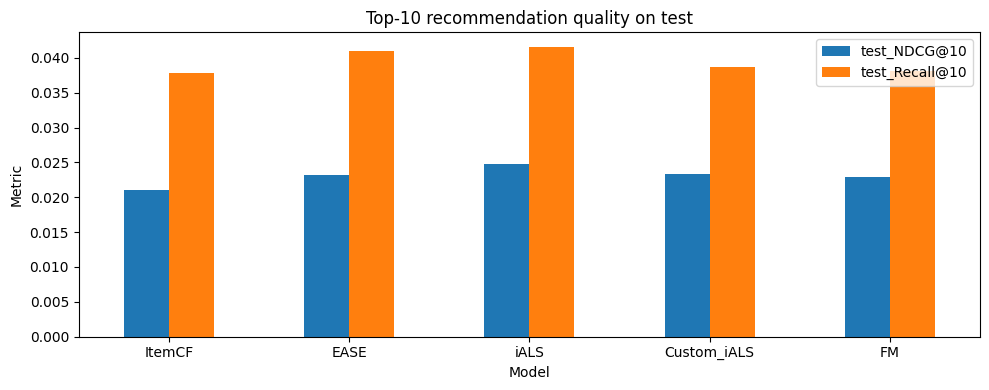

КОНЕЦ ФИНАЛЬНОЙ ОЦЕНКИ


In [6]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MODEL_NAMES = ["ItemCF", "EASE", "iALS", "Custom_iALS", "FM"]

# Проверяем, что настройки не менялись после выбора на validation.
with open("results/best_parameters.json", encoding="utf-8") as file:
    frozen_parameters = json.load(file)

assert frozen_parameters == best_parameters
assert all(name in best_models for name in MODEL_NAMES)

test_truth = make_truth(test)
assert len(test_truth) == 2918

for user, relevant in test_truth.items():
    assert not relevant.intersection(X[user].indices)

test_rows = []

for name in MODEL_NAMES:
    print(f"Оценка {name} на test...", flush=True)

    started = time.perf_counter()
    metrics = evaluate(best_models[name], test_truth, X)
    elapsed = time.perf_counter() - started

    parameters_json = json.dumps(
        best_parameters[name], sort_keys=True
    )

    selected_validation = validation_results[
        (validation_results["model"] == name)
        & (validation_results["parameters"] == parameters_json)
    ]
    assert len(selected_validation) == 1

    selected_row = selected_validation.iloc[0]

    test_rows.append({
        "model": name,
        "validation_NDCG@10": selected_row["NDCG@10"],
        "validation_Recall@10": selected_row["Recall@10"],
        "test_NDCG@10": metrics["NDCG@10"],
        "test_Recall@10": metrics["Recall@10"],
        "evaluated_users": metrics["evaluated_users"],
        "fit_seconds": selected_row["fit_seconds"],
        "test_evaluation_seconds": elapsed,
        "parameters": parameters_json
    })

final_results = pd.DataFrame(test_rows)
final_results.to_csv("results/final_comparison.csv", index=False)

# Контрольный вариант FM: настройки уже выбраны, ничего не подбираем.
id_only_test = evaluate(fm_id_only, test_truth, X)
fm_test = final_results.set_index("model").loc["FM"]

metadata_test = pd.DataFrame([
    {
        "variant": "FM with metadata",
        "NDCG@10": fm_test["test_NDCG@10"],
        "Recall@10": fm_test["test_Recall@10"]
    },
    {
        "variant": "FM ID only",
        "NDCG@10": id_only_test["NDCG@10"],
        "Recall@10": id_only_test["Recall@10"]
    }
])
metadata_test.to_csv("results/metadata_ablation_test.csv", index=False)

# Для обеих ALS выбрана одна и та же конфигурация.
assert best_parameters["iALS"] == best_parameters["Custom_iALS"]

custom_target_test = final_results[
    final_results["model"].isin(["iALS", "Custom_iALS"])
][["model", "test_NDCG@10", "test_Recall@10"]].copy()

custom_target_test.to_csv(
    "results/custom_target_test.csv", index=False
)

print("\nФИНАЛЬНОЕ СРАВНЕНИЕ")
display(
    final_results.sort_values(
        "test_NDCG@10", ascending=False
    ).reset_index(drop=True)
)

print("\nВЛИЯНИЕ МЕТАДАННЫХ НА TEST")
display(metadata_test)

print("\nВЛИЯНИЕ СОБСТВЕННОГО ТАРГЕТА НА TEST")
display(custom_target_test)

plot_data = final_results.set_index("model")[
    ["test_NDCG@10", "test_Recall@10"]
]
plot_data.plot.bar(figsize=(10, 4), rot=0)
plt.title("Top-10 recommendation quality on test")
plt.ylabel("Metric")
plt.xlabel("Model")
plt.tight_layout()
plt.show()

print("КОНЕЦ ФИНАЛЬНОЙ ОЦЕНКИ")

## 7. Выводы

1. На validation максимальный NDCG@10 у ItemCF с 50 соседями — 0,035819. EASE с регуляризацией 500 и iALS с регуляризацией 10 близки: 0,035765 и 0,035758. Статистическую значимость этих различий не проверяли.
2. На test лучший результат среди пяти методов у базового iALS: NDCG@10 = 0,024708, Recall@10 = 0,041601. На выбранной конфигурации он обучился примерно за 14,5 секунды. EASE существенно быстрее обучался, но уступил по NDCG@10.
3. Собственный таргет не улучшил качество. При одинаковых настройках NDCG@10 снизился с 0,024708 до 0,023412, Recall@10 — с 0,041601 до 0,038647. На validation направление такое же. Использование силы оценки в предложенной форме оказалось хуже бинарного сигнала; почему именно — отдельным экспериментом не установлено.
4. Метаданные тоже не дали однозначного улучшения. На validation FM с метаданными уступила ID-only по обеим метрикам. На test её NDCG@10 ниже (0,022886 против 0,023200), а Recall@10 немного выше (0,038073 против 0,037694). В рамках этого короткого подбора устойчивой пользы от бренда и категорий не обнаружено.
5. У всех пяти выбранных моделей качество на test ниже, чем на validation. Периоды и пользователи различаются; возможны временные изменения поведения, но причинный вывод по этому сравнению сделать нельзя.

Ограничения: отбор популярных товаров, много исключённых новых пользователей, только один временной split и seed, небольшой поиск параметров, неполные метаданные и их статический снимок, отсутствие доверительных интервалов. Низкая доля найденных релевантных товаров показывает, что результаты нельзя считать высоким качеством промышленной системы.

## Источники методов

- Данные: Jianmo Ni, Amazon Review Data (2018), https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/
- Item-based CF: Sarwar et al., Item-Based Collaborative Filtering Recommendation Algorithms (2001), https://files.grouplens.org/papers/www10_sarwar.pdf
- iALS: Hu, Koren, Volinsky, Collaborative Filtering for Implicit Feedback Datasets (2008), https://chrisvolinsky.com/files/publications/Collaborative_Filtering_for_Implicit_Feedback_Datasets.pdf
- EASE: Steck, Embarrassingly Shallow Autoencoders for Sparse Data (2019), https://arxiv.org/abs/1905.03375
- FM: Rendle, Factorization Machines (2010), https://www.ismll.uni-hildesheim.de/pub/pdfs/Rendle2010FM.pdf
